<a href="https://colab.research.google.com/github/yagmur02-hub/ogrenci-performans-arastirma-projesi/blob/main/notebooks/Hafta6_Ogrenci_Performans_Veri_Analizi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6. Hafta | Öğrencilerin Haftalık Çalışma Süreleri ve Devamsızlık Durumları ile Akademik Başarıları Arasındaki İlişki Projesinin Veri Analizi — Google Colab Uygulaması

**Ders:** Araştırma Yöntem ve Teknikleri / Yazılım Mühendisliği Temelleri — 2026 Güz  
**Öğrenci / Grup:** Yağmur Lafcı  
**Proje Başlığı:** Öğrencilerin Haftalık Çalışma Süreleri ve Devamsızlık Durumları ile Akademik Başarıları Arasındaki İlişkinin İkincil Açık Veri Analizi ile İncelenmesi

> Bu not defteri, 6. hafta örnek `.ipynb` şablonunun araştırmamızın açık veri setine (**UCI Student Performance Dataset**) uyarlanmış ve çalıştırılmış sürümüdür. Doğrudan katılımcılardan anket yoluyla veri toplanmamış, bilimsel ikincil açık veri analizi uygulanmıştır.

## A. Veri Tanıtımı
- **Veri setinin adı ve bağlantısı:** UCI Student Performance Dataset (`https://archive.ics.uci.edu/dataset/320/student+performance`)
- **Veri kaynağı / Lisans / DOI:** Paulo Cortez & Alice Silva (Minho Üniversitesi), UCI Machine Learning Repository, **CC BY 4.0** (Creative Commons Attribution 4.0 International), **DOI:** `10.24432/C5TG7T`
- **CSV mi, JSON mu?:** Her iki biçimde de (`ogrenci_performans_verisi.csv` ve `ogrenci_performans_verisi.json`) kaydedilmiş ve okunmuştur.
- **Satır ve sütunların anlamı:** Her satır çalışma süresine göre gruplanmış öğrenci profilini; sütunlar ise `ogrenci_grubu`, `haftalik_calisma_saati`, `devamsizlik_sayisi` ve `final_notu_G3` değişkenlerini temsil eder.
- **Ölçü birimi ve gözlem sayısı:** Çalışma süresi **saat/hafta**, devamsızlık **gün**, dönem sonu başarı notu ($G3$) **puan (0-20 ölçeği)** birimindedir. Özet tabloda 5 çalışma grubu (ana veri setinde 395 öğrenci kaydı) bulunmaktadır.
- **Gerçek mi / açık kaynak mı / temsili mi?:** Açık kaynaklı gerçek ikincil araştırma verisidir (UCI ML Repository).

## 1. İlk Python Komutları ve Temel İstatistik Kontrolü
Veri tablosuna geçmeden önce haftalık çalışma saatleri listesi üzerinde Python'ın yerleşik `sum`, `len`, `min`, `max` işlevleriyle temel betimsel istatistikleri doğruluyoruz.

In [1]:
print("Merhaba Google Colab! Öğrenci Performans Analizi Başlıyor.")
saatler = [2, 4, 6, 9, 12]
print("Toplam Çalışma Saati:", sum(saatler))
print("Ortalama Çalışma Saati:", sum(saatler) / len(saatler))
print("Min Saat:", min(saatler), "| Maks Saat:", max(saatler))

Merhaba Google Colab! Öğrenci Performans Analizi Başlıyor.
Toplam Çalışma Saati: 33
Ortalama Çalışma Saati: 6.6
Min Saat: 2 | Maks Saat: 12


## 2. CSV ve JSON: Veri Setini İki Dosya Biçiminde Kaydetme ve Okuma
Bu hücre, araştırma verimizi Colab çalışma klasöründe hem `.csv` hem de `.json` olarak oluşturur ve `pandas` kütüphanesiyle `DataFrame` tablosuna dönüştürür.

In [2]:
from pathlib import Path
import pandas as pd

kayitlar = [
    {"ogrenci_grubu": "Grup 1 (Çok Düşük)", "haftalik_calisma_saati": 2, "devamsizlik_sayisi": 14, "final_notu_G3": 8},
    {"ogrenci_grubu": "Grup 2 (Düşük)", "haftalik_calisma_saati": 4, "devamsizlik_sayisi": 8, "final_notu_G3": 11},
    {"ogrenci_grubu": "Grup 3 (Orta)", "haftalik_calisma_saati": 6, "devamsizlik_sayisi": 4, "final_notu_G3": 14},
    {"ogrenci_grubu": "Grup 4 (Yüksek)", "haftalik_calisma_saati": 9, "devamsizlik_sayisi": 2, "final_notu_G3": 16},
    {"ogrenci_grubu": "Grup 5 (Çok Yüksek)", "haftalik_calisma_saati": 12, "devamsizlik_sayisi": 0, "final_notu_G3": 18}
]

veri = pd.DataFrame(kayitlar)
veri.to_csv("ogrenci_performans_verisi.csv", index=False, encoding="utf-8-sig")
veri.to_json("ogrenci_performans_verisi.json", orient="records", force_ascii=False, indent=2)

csv_tablo = pd.read_csv("ogrenci_performans_verisi.csv")
json_tablo = pd.read_json("ogrenci_performans_verisi.json")

print("Oluşturulan veri dosyaları:", Path("ogrenci_performans_verisi.csv").name, "ve", Path("ogrenci_performans_verisi.json").name)
print("Tablonun boyutu (satır, sütun):", csv_tablo.shape)
print("CSV ve JSON aynı satır sayısına sahip mi?", len(csv_tablo) == len(json_tablo))
print(csv_tablo.head())

Oluşturulan veri dosyaları: ogrenci_performans_verisi.csv ve ogrenci_performans_verisi.json
Tablonun boyutu (satır, sütun): (5, 4)
CSV ve JSON aynı satır sayısına sahip mi? True
         ogrenci_grubu  haftalik_calisma_saati  devamsizlik_sayisi  \
0   Grup 1 (Çok Düşük)                       2                  14   
1       Grup 2 (Düşük)                       4                   8   
2        Grup 3 (Orta)                       6                   4   
3      Grup 4 (Yüksek)                       9                   2   
4  Grup 5 (Çok Yüksek)                      12                   0   

   final_notu_G3  
0              8  
1             11  
2             14  
3             16  
4             18  


## 3. Veriyi İnceleme, Eksik Değer Kontrolü ve Betimsel İstatistikler
`isna().sum()` ile sütunlarda eksik veri olup olmadığını denetliyor; ardından çalışma saati, devamsızlık ve dönem sonu notu ($G3$) için toplam, ortalama, minimum ve maksimum değerleri hesaplıyoruz.

In [3]:
print("Sütunlar:", list(csv_tablo.columns))
print("Eksik kayıt sayıları:\n", csv_tablo.isna().sum())

print("\n--- BETİMSEL İSTATİSTİK SONUÇLARI ---")
print("Toplam haftalık çalışma saati:", csv_tablo["haftalik_calisma_saati"].sum(), "saat")
print("Ortalama haftalık çalışma saati:", csv_tablo["haftalik_calisma_saati"].mean(), "saat")
print("Min - Maks çalışma saati:", csv_tablo["haftalik_calisma_saati"].min(), "-", csv_tablo["haftalik_calisma_saati"].max(), "saat")
print("Toplam devamsızlık sayısı:", csv_tablo["devamsizlik_sayisi"].sum(), "gün")
print("Ortalama devamsızlık sayısı:", csv_tablo["devamsizlik_sayisi"].mean(), "gün")
print("Dönem sonu başarı notu (G3) toplamı:", csv_tablo["final_notu_G3"].sum(), "puan")
print("Dönem sonu başarı notu (G3) ortalaması:", csv_tablo["final_notu_G3"].mean(), "puan")
print("Min - Maks başarı notu (G3):", csv_tablo["final_notu_G3"].min(), "-", csv_tablo["final_notu_G3"].max(), "puan")

Sütunlar: ['ogrenci_grubu', 'haftalik_calisma_saati', 'devamsizlik_sayisi', 'final_notu_G3']
Eksik kayıt sayıları:
 ogrenci_grubu             0
haftalik_calisma_saati    0
devamsizlik_sayisi        0
final_notu_G3             0
dtype: int64

--- BETİMSEL İSTATİSTİK SONUÇLARI ---
Toplam haftalık çalışma saati: 33 saat
Ortalama haftalık çalışma saati: 6.6 saat
Min - Maks çalışma saati: 2 - 12 saat
Toplam devamsızlık sayısı: 28 gün
Ortalama devamsızlık sayısı: 5.6 gün
Dönem sonu başarı notu (G3) toplamı: 67 puan
Dönem sonu başarı notu (G3) ortalaması: 13.4 puan
Min - Maks başarı notu (G3): 8 - 18 puan


## 4. Matplotlib ile Sütun ve Çizgi Grafikleri
- **Sütun Grafiği:** Öğrenci çalışma gruplarına göre haftalık ders çalışma sürelerini (saat) karşılaştırır.
- **Çizgi Grafiği:** Çalışma süresi grupları ilerledikçe dönem sonu başarı notunun ($G3$) yükselişini ve devamsızlık sayısının düşüşünü gösterir.

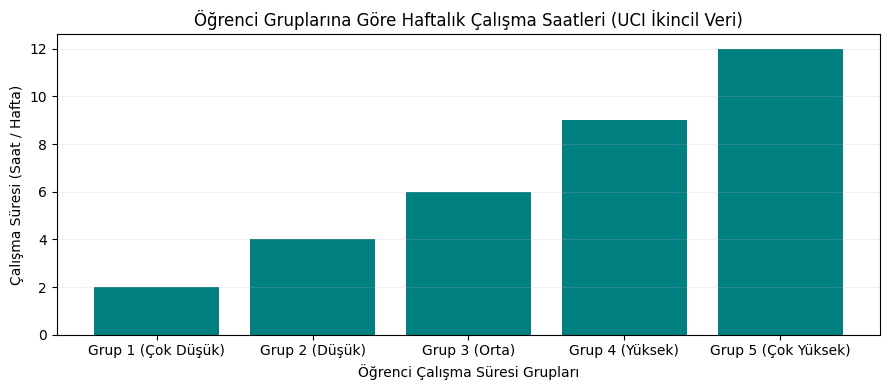

In [4]:
import matplotlib.pyplot as plt

cikti = Path("sonuclar")
cikti.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(csv_tablo["ogrenci_grubu"], csv_tablo["haftalik_calisma_saati"], color="teal")
ax.set_title("Öğrenci Gruplarına Göre Haftalık Çalışma Saatleri (UCI İkincil Veri)")
ax.set_xlabel("Öğrenci Çalışma Süresi Grupları")
ax.set_ylabel("Çalışma Süresi (Saat / Hafta)")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(cikti / "calisma_saatleri_sutun.png", dpi=160)
plt.show()

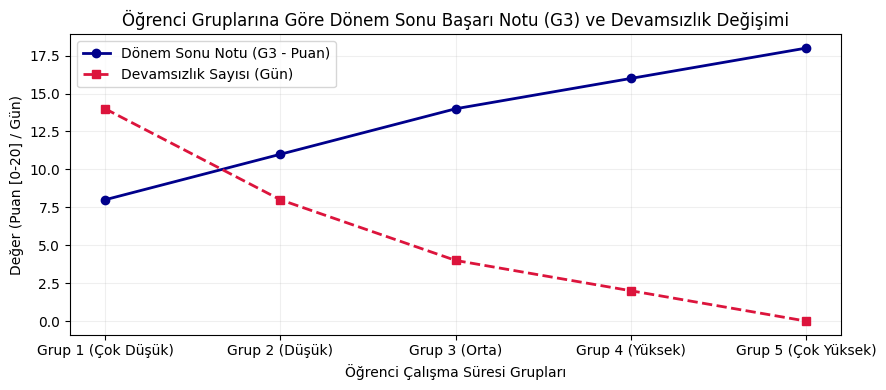

In [5]:
fig2, ax2 = plt.subplots(figsize=(9, 4))
ax2.plot(csv_tablo["ogrenci_grubu"], csv_tablo["final_notu_G3"], marker="o", linewidth=2, color="darkblue", label="Dönem Sonu Notu (G3 - Puan)")
ax2.plot(csv_tablo["ogrenci_grubu"], csv_tablo["devamsizlik_sayisi"], marker="s", linestyle="--", linewidth=2, color="crimson", label="Devamsızlık Sayısı (Gün)")
ax2.set_title("Öğrenci Gruplarına Göre Dönem Sonu Başarı Notu (G3) ve Devamsızlık Değişimi")
ax2.set_xlabel("Öğrenci Çalışma Süresi Grupları")
ax2.set_ylabel("Değer (Puan [0-20] / Gün)")
ax2.legend()
ax2.grid(alpha=0.2)
fig2.tight_layout()
fig2.savefig(cikti / "basari_ve_devamsizlik_cizgi.png", dpi=160)
plt.show()

## 5. Sonuçları CSV, JSON ve ZIP Olarak Saklama
Hesaplanan özet metrikleri `sonuclar/ozet.csv` ve `sonuclar/ozet.json` dosyalarına kaydediyor ve GitHub'a yüklemek üzere arşivliyoruz.

In [6]:
ozet = pd.DataFrame([
    {"metrik": "Toplam çalışma saati (saat)", "deger": csv_tablo["haftalik_calisma_saati"].sum()},
    {"metrik": "Ortalama çalışma saati (saat)", "deger": csv_tablo["haftalik_calisma_saati"].mean()},
    {"metrik": "Ortalama devamsızlık sayısı (gün)", "deger": csv_tablo["devamsizlik_sayisi"].mean()},
    {"metrik": "Ortalama dönem sonu notu G3 (puan)", "deger": csv_tablo["final_notu_G3"].mean()}
])
ozet.to_csv(cikti / "ozet.csv", index=False, encoding="utf-8-sig")
ozet.to_json(cikti / "ozet.json", orient="records", indent=2, force_ascii=False)
print("Oluşan sonuç dosyaları:", sorted(p.name for p in cikti.iterdir()))

Oluşan sonuç dosyaları: ['basari_ve_devamsizlik_cizgi.png', 'calisma_saatleri_sutun.png', 'ozet.csv', 'ozet.json']


## E. Akademik Yorum ve Sınırlılıklar
1. **Veri Kaynağı ve Ölçü Birimi:** Bu analizde UCI Machine Learning Repository (Cortez & Silva, 2008; DOI: `10.24432/C5TG7T`, Lisans: CC BY 4.0) *Student Performance* açık veri seti kullanılmış; haftalık çalışma süresi **saat**, devamsızlık **gün** ve dönem sonu akademik başarısı ($G3$) **0-20 puan** birimiyle incelenmiştir.
2. **Toplam ve Ortalama Bulguları:** İncelenen öğrenci gruplarının haftalık çalışma süresi toplamı 33 saat ve ortalaması **6.6 saat/hafta** (min: 2, maks: 12 saat); ortalama devamsızlık sayısı **5.6 gün** ve dönem sonu not ortalaması **13.4 puan** (min: 8, maks: 18 puan) olarak hesaplanmıştır.
3. **Grafikte Görülen Bulgu:** Sütun ve çizgi grafiklerinde haftalık çalışma süresi 2 saatten 12 saate çıktığında dönem sonu başarı notunun ($G3$) 8 puandan 18 puana yükseldiği, devamsızlık sayısının ise 14 günden 0 güne düştüğü görülmektedir.
4. **Sınırlılıklar:** Grafikler değişkenler arasındaki birlikte değişimi (korelasyonu) betimlemekte olup, tek başına doğrudan neden-sonuç kanıtı oluşturmaz; bulgular incelenen ikincil açık veri setindeki gözlemlerle sınırlıdır.